In [1]:
import os
import time
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from PIL import Image
from tqdm.auto import tqdm

In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
coco_path = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017"
train_path = os.path.join(coco_path, "train2017")

import os

COCO_ROOT = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017"

TRAIN_IMG_DIR = os.path.join(COCO_ROOT, "train2017")
TRAIN_ANN_FILE = os.path.join(
    COCO_ROOT, "annotations", "captions_train2017.json"
)

VAL_IMG_DIR = os.path.join(COCO_ROOT, "val2017")
VAL_ANN_FILE = os.path.join(
    COCO_ROOT, "annotations", "captions_val2017.json"
)

COCO contents:
['val2017', 'annotations', 'test2017', 'train2017']

Train images found: 118287


In [7]:
EMBED_DIM = 384


class ImageProjection(nn.Module):
    def __init__(self, input_dim=768, output_dim=384):
        super().__init__()

        self.projection = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        x = self.projection(x)
        x = F.normalize(x, dim=-1)
        return x


image_projection = ImageProjection(
    input_dim=768,
    output_dim=384
)

dummy_features = torch.randn(32, 768)

image_embeddings = image_projection(dummy_features)

# CLIMP

IMG_DIR = TRAIN_IMG_DIR
ANN_FILE = TRAIN_ANN_FILE

CHECKPOINT_DIR = "/kaggle/working/checkpoints"

VISION_MODEL = "saurabhati/VMamba_ImageNet_82.6"
TEXT_MODEL = "state-spaces/mamba-130m-hf"

BATCH_SIZE = 32
LATENT_DIM = 384
LR = 3e-4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Vision model:", VISION_MODEL)
print("Text model:", TEXT_MODEL)
print("Batch size:", BATCH_SIZE)
print("Latent dimension:", LATENT_DIM)
print("Learning rate:", LR)
print("Device:", DEVICE)


Input shape: torch.Size([32, 768])
Output shape: torch.Size([32, 384])
Embedding norm: 0.9999999403953552


In [10]:
!pip install -q mamba-ssm --no-build-isolation
import mamba_ssm

print("mamba_ssm imported successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.4/216.4 kB 12.4 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.5/728.5 kB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.5/88.5 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 772.4/772.4 kB 42.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.3/29.3 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.8/897.8 kB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 90.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 14.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the pa

In [11]:
from transformers import AutoModelForImageClassification, AutoModel

#PATCH 1:
import mamba_ssm
try:
    from mamba_ssm.ops.selective_scan_interface import selective_scan_fn, mamba_inner_fn
    from mamba_ssm.ops.triton.selective_state_update import selective_state_update
    
    mamba_ssm.selective_scan_fn = selective_scan_fn
    mamba_ssm.mamba_inner_fn = mamba_inner_fn
    mamba_ssm.selective_state_update = selective_state_update
    print("✅ Successfully linked mamba-ssm CUDA kernels!")
except ImportError as e:
    print(f"⚠️ Warning: Could not link CUDA kernels. Error: {e}")


class CLIMP(nn.Module):
    def __init__(self, vision_model_name, text_model_name, latent_dim):
        super().__init__()
        
        #PATCH 2:
        _orig_linspace = torch.linspace
        def _cpu_linspace(*args, **kwargs):
            if kwargs.get("device") is None:
                kwargs["device"] = torch.device("cpu")
            return _orig_linspace(*args, **kwargs)
        
        torch.linspace = _cpu_linspace
        
        try:
            # 1. Vision Backbone (Frozen)
            self.vision_backbone = AutoModelForImageClassification.from_pretrained(
                vision_model_name, 
                trust_remote_code=True,
                low_cpu_mem_usage=False,
                _fast_init=False
            )
        finally:

            torch.linspace = _orig_linspace
      
        if hasattr(self.vision_backbone, 'head'):
            vision_feat_dim = self.vision_backbone.head.in_features
            self.vision_backbone.head = nn.Identity()
        elif hasattr(self.vision_backbone, 'classifier'):
            vision_feat_dim = self.vision_backbone.classifier.in_features
            self.vision_backbone.classifier = nn.Identity()
        else:
            vision_feat_dim = self.vision_backbone.config.hidden_size 
            
        # 2. Text Backbone (Frozen)
        self.text_backbone = AutoModel.from_pretrained(
            text_model_name,
            trust_remote_code=True,
            low_cpu_mem_usage=False, 
            _fast_init=False
        )
        text_feat_dim = self.text_backbone.config.hidden_size
        

        for param in self.vision_backbone.parameters():
            param.requires_grad = False
        for param in self.text_backbone.parameters():
            param.requires_grad = False
            
        # 3. Projection Heads
        self.vision_proj = nn.Linear(vision_feat_dim, latent_dim)
        self.text_proj = nn.Linear(text_feat_dim, latent_dim)
        
     
        self.logit_scale = nn.Parameter(torch.ones([]) * 2.6592) 
        
    def forward(self, images, input_ids, attention_mask):
     
        with torch.no_grad():
            v_out = self.vision_backbone(images)
            v_features = v_out.logits if hasattr(v_out, 'logits') else v_out 
            
    
        with torch.no_grad():
            t_out = self.text_backbone(input_ids=input_ids, attention_mask=attention_mask)
            t_hidden = t_out.last_hidden_state if hasattr(t_out, 'last_hidden_state') else t_out[0]
            
            mask_expanded = attention_mask.unsqueeze(-1).expand(t_hidden.size()).float()
            t_features = torch.sum(t_hidden * mask_expanded, 1) / torch.clamp(mask_expanded.sum(1), min=1e-9)

        image_embeds = F.normalize(self.vision_proj(v_features), p=2, dim=-1)
        text_embeds = F.normalize(self.text_proj(t_features), p=2, dim=-1)
        
        return image_embeds, text_embeds, self.logit_scale.exp()

✅ Successfully linked mamba-ssm CUDA kernels!


In [12]:

model = CLIMP(
    vision_model_name=VISION_MODEL,
    text_model_name=TEXT_MODEL,
    latent_dim=LATENT_DIM
).to(DEVICE)

print("CLIMP model loaded successfully!")

config.json: 0.00B [00:00, ?B/s]

configuration_vmamba.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/saurabhati/VMamba_ImageNet_82.6:
- configuration_vmamba.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_vmamba.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/saurabhati/VMamba_ImageNet_82.6:
- modeling_vmamba.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
/root/.cache/huggingface/modules/transformers_modules/saurabhati/VMamba_ImageNet_82_dot_6/3db342a1b00a91c350dca4df93a1645ad2ac9493/modeling_vmamba.py:694: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/root/.cache/huggingface/modules/transformers_modules/saurabhati/VMamba_ImageNet_82_dot_6/3db342a1b00a91c350dca4df93a1645ad2ac9493/modeling_vmamba.py:709: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd


model.safetensors:   0%|          | 0.00/121M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/517M [00:00<?, ?B/s]

The fast path is not available because one of `(selective_state_update, selective_scan_fn, causal_conv1d_fn, causal_conv1d_update, mamba_inner_fn)` is None. Falling back to the sequential implementation of Mamba, as use_mambapy is set to False. To install follow https://github.com/state-spaces/mamba/#installation for mamba-ssm and install the kernels library using `pip install kernels` or https://github.com/Dao-AILab/causal-conv1d for causal-conv1d. For the mamba.py backend, follow https://github.com/alxndrTL/mamba.py.


Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

CLIMP model loaded successfully!


In [13]:
print("Vision feature dimension:",
      model.vision_proj.in_features)

print("Text feature dimension:",
      model.text_proj.in_features)

print("CLIMP embedding dimension:",
      model.vision_proj.out_features)

print("Initial logit scale:",
      model.logit_scale.exp().item())

Vision feature dimension: 768
Text feature dimension: 768
CLIMP embedding dimension: 384
Initial logit scale: 14.284856796264648


In [14]:
trainable_params = 0
frozen_params = 0

for name, param in model.named_parameters():
    if param.requires_grad:
        trainable_params += param.numel()
        print("TRAINABLE:", name, param.shape)
    else:
        frozen_params += param.numel()

print("\nTrainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)

TRAINABLE: logit_scale torch.Size([])
TRAINABLE: vision_proj.weight torch.Size([384, 768])
TRAINABLE: vision_proj.bias torch.Size([384])
TRAINABLE: text_proj.weight torch.Size([384, 768])
TRAINABLE: text_proj.bias torch.Size([384])

Trainable parameters: 590593
Frozen parameters: 158615424


In [15]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded!")
print("Vocabulary size:", len(tokenizer))
print("Pad token:", tokenizer.pad_token)
print("EOS token:", tokenizer.eos_token)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded!
Vocabulary size: 50277
Pad token: <|endoftext|>
EOS token: <|endoftext|>


In [16]:
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import torchvision.transforms as T

from transformers import (
    AutoModelForImageClassification,
    AutoModel,
    AutoTokenizer
)

from tqdm import tqdm

print("All imports loaded successfully!")

All imports loaded successfully!


In [17]:
class COCODataset(Dataset):
    def __init__(self, img_dir, ann_file, tokenizer):
        self.img_dir = img_dir

        with open(ann_file, 'r') as f:
            data = json.load(f)

        # image_id → filename
        self.img_map = {
            img['id']: img['file_name']
            for img in data['images']
        }

        self.annotations = data['annotations']

        self.preprocess = T.Compose([
            T.Resize(224, interpolation=Image.BICUBIC),
            T.CenterCrop(224),
            T.ToTensor(),
            T.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        ann = self.annotations[idx]

        img_filename = self.img_map[ann['image_id']]
        img_path = os.path.join(self.img_dir, img_filename)

        image = Image.open(img_path).convert('RGB')
        image = self.preprocess(image)

        text = ann['caption']

        text_inputs = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=64,
            return_tensors="pt"
        )

        return {
            'image': image,
            'input_ids': text_inputs['input_ids'].squeeze(0),
            'attention_mask': text_inputs['attention_mask'].squeeze(0)
        }

In [18]:
train_dataset = COCODataset(
    IMG_DIR,
    ANN_FILE,
    tokenizer
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Dataset size:", len(train_dataset))
print("Number of batches:", len(train_loader))

Dataset size: 591753
Number of batches: 18492


In [19]:
batch = next(iter(train_loader))

images = batch["image"].to(DEVICE)
input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)

print("Images:", images.shape)
print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)

Images: torch.Size([32, 3, 224, 224])
Input IDs: torch.Size([32, 64])
Attention mask: torch.Size([32, 64])


In [20]:
train_dataset = COCODataset(
    IMG_DIR,
    ANN_FILE,
    tokenizer
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Dataset size:", len(train_dataset))
print("Number of batches:", len(train_loader))

Dataset size: 591753
Number of batches: 18492


In [22]:
#CLIMP forward pass

model.eval()

with torch.no_grad():
    image_embeds, text_embeds, logit_scale = model(
        images,
        input_ids,
        attention_mask
    )

print("Image embeddings:", image_embeds.shape)
print("Text embeddings:", text_embeds.shape)
print("Logit scale:", logit_scale.item())

Image embeddings: torch.Size([32, 384])
Text embeddings: torch.Size([32, 384])
Logit scale: 14.284856796264648


In [23]:
def info_nce_loss(image_embeds, text_embeds, logit_scale):
  
    logits_per_image = logit_scale * image_embeds @ text_embeds.t()

    logits_per_text = logits_per_image.t()

    labels = torch.arange(
        len(logits_per_image),
        device=logits_per_image.device
    )

    loss_i = F.cross_entropy(logits_per_image, labels)
    loss_t = F.cross_entropy(logits_per_text, labels)

    return (loss_i + loss_t) / 2

loss = info_nce_loss(
    image_embeds,
    text_embeds,
    logit_scale
)

print("Initial InfoNCE loss:", loss.item())

Initial InfoNCE loss: 3.6604254245758057


In [24]:
model.train()

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.01
)


vision_proj_before = model.vision_proj.weight.detach().clone()
text_proj_before = model.text_proj.weight.detach().clone()
logit_scale_before = model.logit_scale.detach().clone()

# Forward pass
image_embeds, text_embeds, logit_scale = model(
    images,
    input_ids,
    attention_mask
)

#loss
loss = info_nce_loss(
    image_embeds,
    text_embeds,
    logit_scale
)

# Backpropagation
optimizer.zero_grad()
loss.backward()

#gradients
print("Vision projection gradient:",
      model.vision_proj.weight.grad.norm().item())

print("Text projection gradient:",
      model.text_proj.weight.grad.norm().item())

print("Logit scale gradient:",
      model.logit_scale.grad.item())

# Update parameters
optimizer.step()

print("\nLoss before update:", loss.item())

Vision projection gradient: 3.5599091053009033
Text projection gradient: 3.666581630706787
Logit scale gradient: 0.40800565481185913

Loss before update: 3.6796302795410156


In [25]:
print(
    "Vision projection changed:",
    not torch.equal(
        vision_proj_before,
        model.vision_proj.weight
    )
)

print(
    "Text projection changed:",
    not torch.equal(
        text_proj_before,
        model.text_proj.weight
    )
)

print(
    "Logit scale changed:",
    not torch.equal(
        logit_scale_before,
        model.logit_scale
    )
)

Vision projection changed: True
Text projection changed: True
Logit scale changed: True


In [26]:
# Reinitialize

model = CLIMP(
    vision_model_name=VISION_MODEL,
    text_model_name=TEXT_MODEL,
    latent_dim=LATENT_DIM
).to(DEVICE)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.01
)

print("Model reinitialized.")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/276 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

Model reinitialized.
Trainable parameters: 590593


In [27]:
from time import time

EPOCHS = 2
SAVE_EVERY = 2000

model.train()

global_step = 0
epoch_losses = []

print("Starting CLIMP training...")
print(f"Epochs: {EPOCHS}")
print(f"Batches per epoch: {len(train_loader)}")
print(f"Batch size: {BATCH_SIZE}")

training_start = time()

for epoch in range(EPOCHS):

    epoch_start = time()
    running_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress_bar):

        images = batch["image"].to(DEVICE, non_blocking=True)
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        image_embeds, text_embeds, logit_scale = model(
            images,
            input_ids,
            attention_mask
        )

        # InfoNCE
        loss = info_nce_loss(
            image_embeds,
            text_embeds,
            logit_scale
        )

        # Backpropagation
        loss.backward()
        optimizer.step()

        loss_value = loss.item()
        running_loss += loss_value
        global_step += 1

        progress_bar.set_postfix(
            loss=f"{loss_value:.4f}"
        )

        #checkpoint
        if global_step % SAVE_EVERY == 0:

            checkpoint_path = os.path.join(
                CHECKPOINT_DIR,
                f"climp_step_{global_step}.pt"
            )

            torch.save({
                "epoch": epoch + 1,
                "step": global_step,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "loss": loss_value,
            }, checkpoint_path)

            print(
                f"\nCheckpoint saved: {checkpoint_path}"
                f" | Loss: {loss_value:.4f}"
            )

    avg_loss = running_loss / len(train_loader)
    epoch_losses.append(avg_loss)

    epoch_time = time() - epoch_start

    print(
        f"\nEpoch {epoch + 1} complete | "
        f"Average loss: {avg_loss:.4f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

total_time = time() - training_start

print("\nTraining complete!")
print(f"Total time: {total_time / 60:.2f} minutes")
print(f"Final average loss: {epoch_losses[-1]:.4f}")

Starting CLIMP training...
Epochs: 2
Batches per epoch: 18492
Batch size: 32


Epoch 1/2:  11%|█         | 2000/18492 [26:37<4:48:36,  1.05s/it, loss=0.9923]


Checkpoint saved: /kaggle/working/checkpoints/climp_step_2000.pt | Loss: 0.9923


Epoch 1/2:  22%|██▏       | 4000/18492 [53:19<4:14:13,  1.05s/it, loss=0.5453]


Checkpoint saved: /kaggle/working/checkpoints/climp_step_4000.pt | Loss: 0.5453


Epoch 1/2:  32%|███▏      | 6000/18492 [1:20:00<3:40:32,  1.06s/it, loss=0.5367]

... (31 outputs left out)

Epoch 2/2:  95%|█████████▍| 17508/18492 [3:53:37<17:31,  1.07s/it, loss=0.6248]


Checkpoint saved: /kaggle/working/checkpoints/climp_step_36000.pt | Loss: 0.6248


Epoch 2/2: 100%|██████████| 18492/18492 [4:06:44<00:00,  1.25it/s, loss=0.3057]


Epoch 2 complete | Average loss: 0.5129 | Time: 246.75 min

Training complete!
Total time: 493.42 minutes
Final average loss: 0.5129


In [28]:
FINAL_WTS_PATH = "/kaggle/working/climp_final_weights.pt"

torch.save(
    model.state_dict(),
    FINAL_WTS_PATH
)

print("Final CLIMP weights saved!")
print(FINAL_WTS_PATH)

Final CLIMP weights saved!
/kaggle/working/climp_final_weights.pt


In [29]:
FINAL_CHECKPOINT_PATH = "/kaggle/working/climp_final_checkpoint.pt"

torch.save({
    "epoch": 1,
    "step": global_step,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "loss": loss_value,
    "vision_model": VISION_MODEL,
    "text_model": TEXT_MODEL,
    "latent_dim": LATENT_DIM,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
}, FINAL_CHECKPOINT_PATH)

print("Final checkpoint saved!")

# Validation dataset paths

VAL_IMG_DIR = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017/"
VAL_ANN_FILE = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_val2017.json"

print("Validation images:", VAL_IMG_DIR)
print("Validation annotations:", VAL_ANN_FILE)

print("\nFiles exist?")
print("Validation images:", os.path.exists(VAL_IMG_DIR))
print("Validation annotations:", os.path.exists(VAL_ANN_FILE))

Final checkpoint saved!


In [31]:
val_dataset = COCODataset(
    VAL_IMG_DIR,
    VAL_ANN_FILE,
    tokenizer
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

print("Validation dataset size:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation dataset size: 25014
Validation batches: 782


In [32]:
model.eval()

all_image_embeds = []
all_text_embeds = []
all_image_ids = []

with torch.no_grad():

    for batch in tqdm(val_loader, desc="Extracting validation embeddings"):

        images = batch["image"].to(DEVICE, non_blocking=True)
        input_ids = batch["input_ids"].to(DEVICE, non_blocking=True)
        attention_mask = batch["attention_mask"].to(
            DEVICE, non_blocking=True
        )

        image_embeds, text_embeds, logit_scale = model(
            images,
            input_ids,
            attention_mask
        )

        all_image_embeds.append(image_embeds.cpu())
        all_text_embeds.append(text_embeds.cpu())

all_image_embeds = torch.cat(all_image_embeds, dim=0)
all_text_embeds = torch.cat(all_text_embeds, dim=0)

print("Image embeddings:", all_image_embeds.shape)
print("Text embeddings:", all_text_embeds.shape)
print("Logit scale:", logit_scale.item())

Extracting validation embeddings: 100%|██████████| 782/782 [10:24<00:00,  1.25it/s]

Image embeddings: torch.Size([25014, 384])
Text embeddings: torch.Size([25014, 384])
Logit scale: 25.233232498168945


In [34]:
image_id_to_index = {}

for idx, image_id in enumerate(val_image_ids):
    if image_id not in image_id_to_index:
        image_id_to_index[image_id] = idx

unique_image_indices = list(image_id_to_index.values())

unique_image_embeds = all_image_embeds[unique_image_indices]

unique_image_ids = list(image_id_to_index.keys())

print("Unique image embeddings:", unique_image_embeds.shape)
print("Unique image IDs:", len(unique_image_ids))

Unique image embeddings: torch.Size([5000, 384])
Unique image IDs: 5000


In [35]:
K_VALUES = [1, 5, 10]

similarities = unique_image_embeds @ all_text_embeds.T

print("Similarity matrix:", similarities.shape)

caption_image_ids = torch.tensor(val_image_ids)

image_id_to_row = {
    image_id: idx
    for idx, image_id in enumerate(unique_image_ids)
}

image_to_text_results = {}

for k in K_VALUES:

    correct = 0
    topk_indices = torch.topk(
        similarities,
        k=k,
        dim=1
    ).indices

    for image_row in range(len(unique_image_ids)):

        image_id = unique_image_ids[image_row]

        retrieved_caption_indices = topk_indices[image_row]

        retrieved_image_ids = caption_image_ids[
            retrieved_caption_indices
        ]


        if (retrieved_image_ids == image_id).any():
            correct += 1

    recall = correct / len(unique_image_ids)

    image_to_text_results[k] = recall

    print(
        f"Image → Text Recall@{k}: "
        f"{recall:.4f} "
        f"({recall * 100:.2f}%)"
    )

Similarity matrix: torch.Size([5000, 25014])
Image → Text Recall@1: 0.1260 (12.60%)
Image → Text Recall@5: 0.3352 (33.52%)
Image → Text Recall@10: 0.4662 (46.62%)


In [36]:
text_to_image_results = {}

for k in K_VALUES:

    correct = 0

    topk_indices = torch.topk(
        similarities,
        k=k,
        dim=0
    ).indices

    for caption_idx in range(len(val_image_ids)):

        ground_truth_image_id = val_image_ids[caption_idx]

        retrieved_image_rows = topk_indices[:, caption_idx]

        retrieved_image_ids = [
            unique_image_ids[row.item()]
            for row in retrieved_image_rows
        ]

        if ground_truth_image_id in retrieved_image_ids:
            correct += 1

    recall = correct / len(val_image_ids)

    text_to_image_results[k] = recall

    print(
        f"Text → Image Recall@{k}: "
        f"{recall:.4f} "
        f"({recall * 100:.2f}%)"
    )

Text → Image Recall@1: 0.0941 (9.41%)
Text → Image Recall@5: 0.2770 (27.70%)
Text → Image Recall@10: 0.4072 (40.72%)


In [37]:
#model weights
FULL_WTS_PATH = "/kaggle/working/climp_final_full_weights.pt"

torch.save(
    model.state_dict(),
    FULL_WTS_PATH
)

print("Full model weights saved:")
print(FULL_WTS_PATH)

import os
size_mb = os.path.getsize(FULL_WTS_PATH) / (1024 ** 2)
print(f"File size: {size_mb:.2f} MB")

Full model weights saved:
/kaggle/working/climp_final_full_weights.pt
File size: 607.53 MB


In [38]:

CLIMP_WTS_PATH = "/kaggle/working/climp_trainable_weights.pt"

trainable_state_dict = {
    name: param.detach().cpu()
    for name, param in model.named_parameters()
    if param.requires_grad
}

torch.save(
    trainable_state_dict,
    CLIMP_WTS_PATH
)

print("Trainable CLIMP weights saved:")
print(CLIMP_WTS_PATH)

size_mb = os.path.getsize(CLIMP_WTS_PATH) / (1024 ** 2)
print(f"File size: {size_mb:.2f} MB")

Trainable CLIMP weights saved:
/kaggle/working/climp_trainable_weights.pt
File size: 2.26 MB


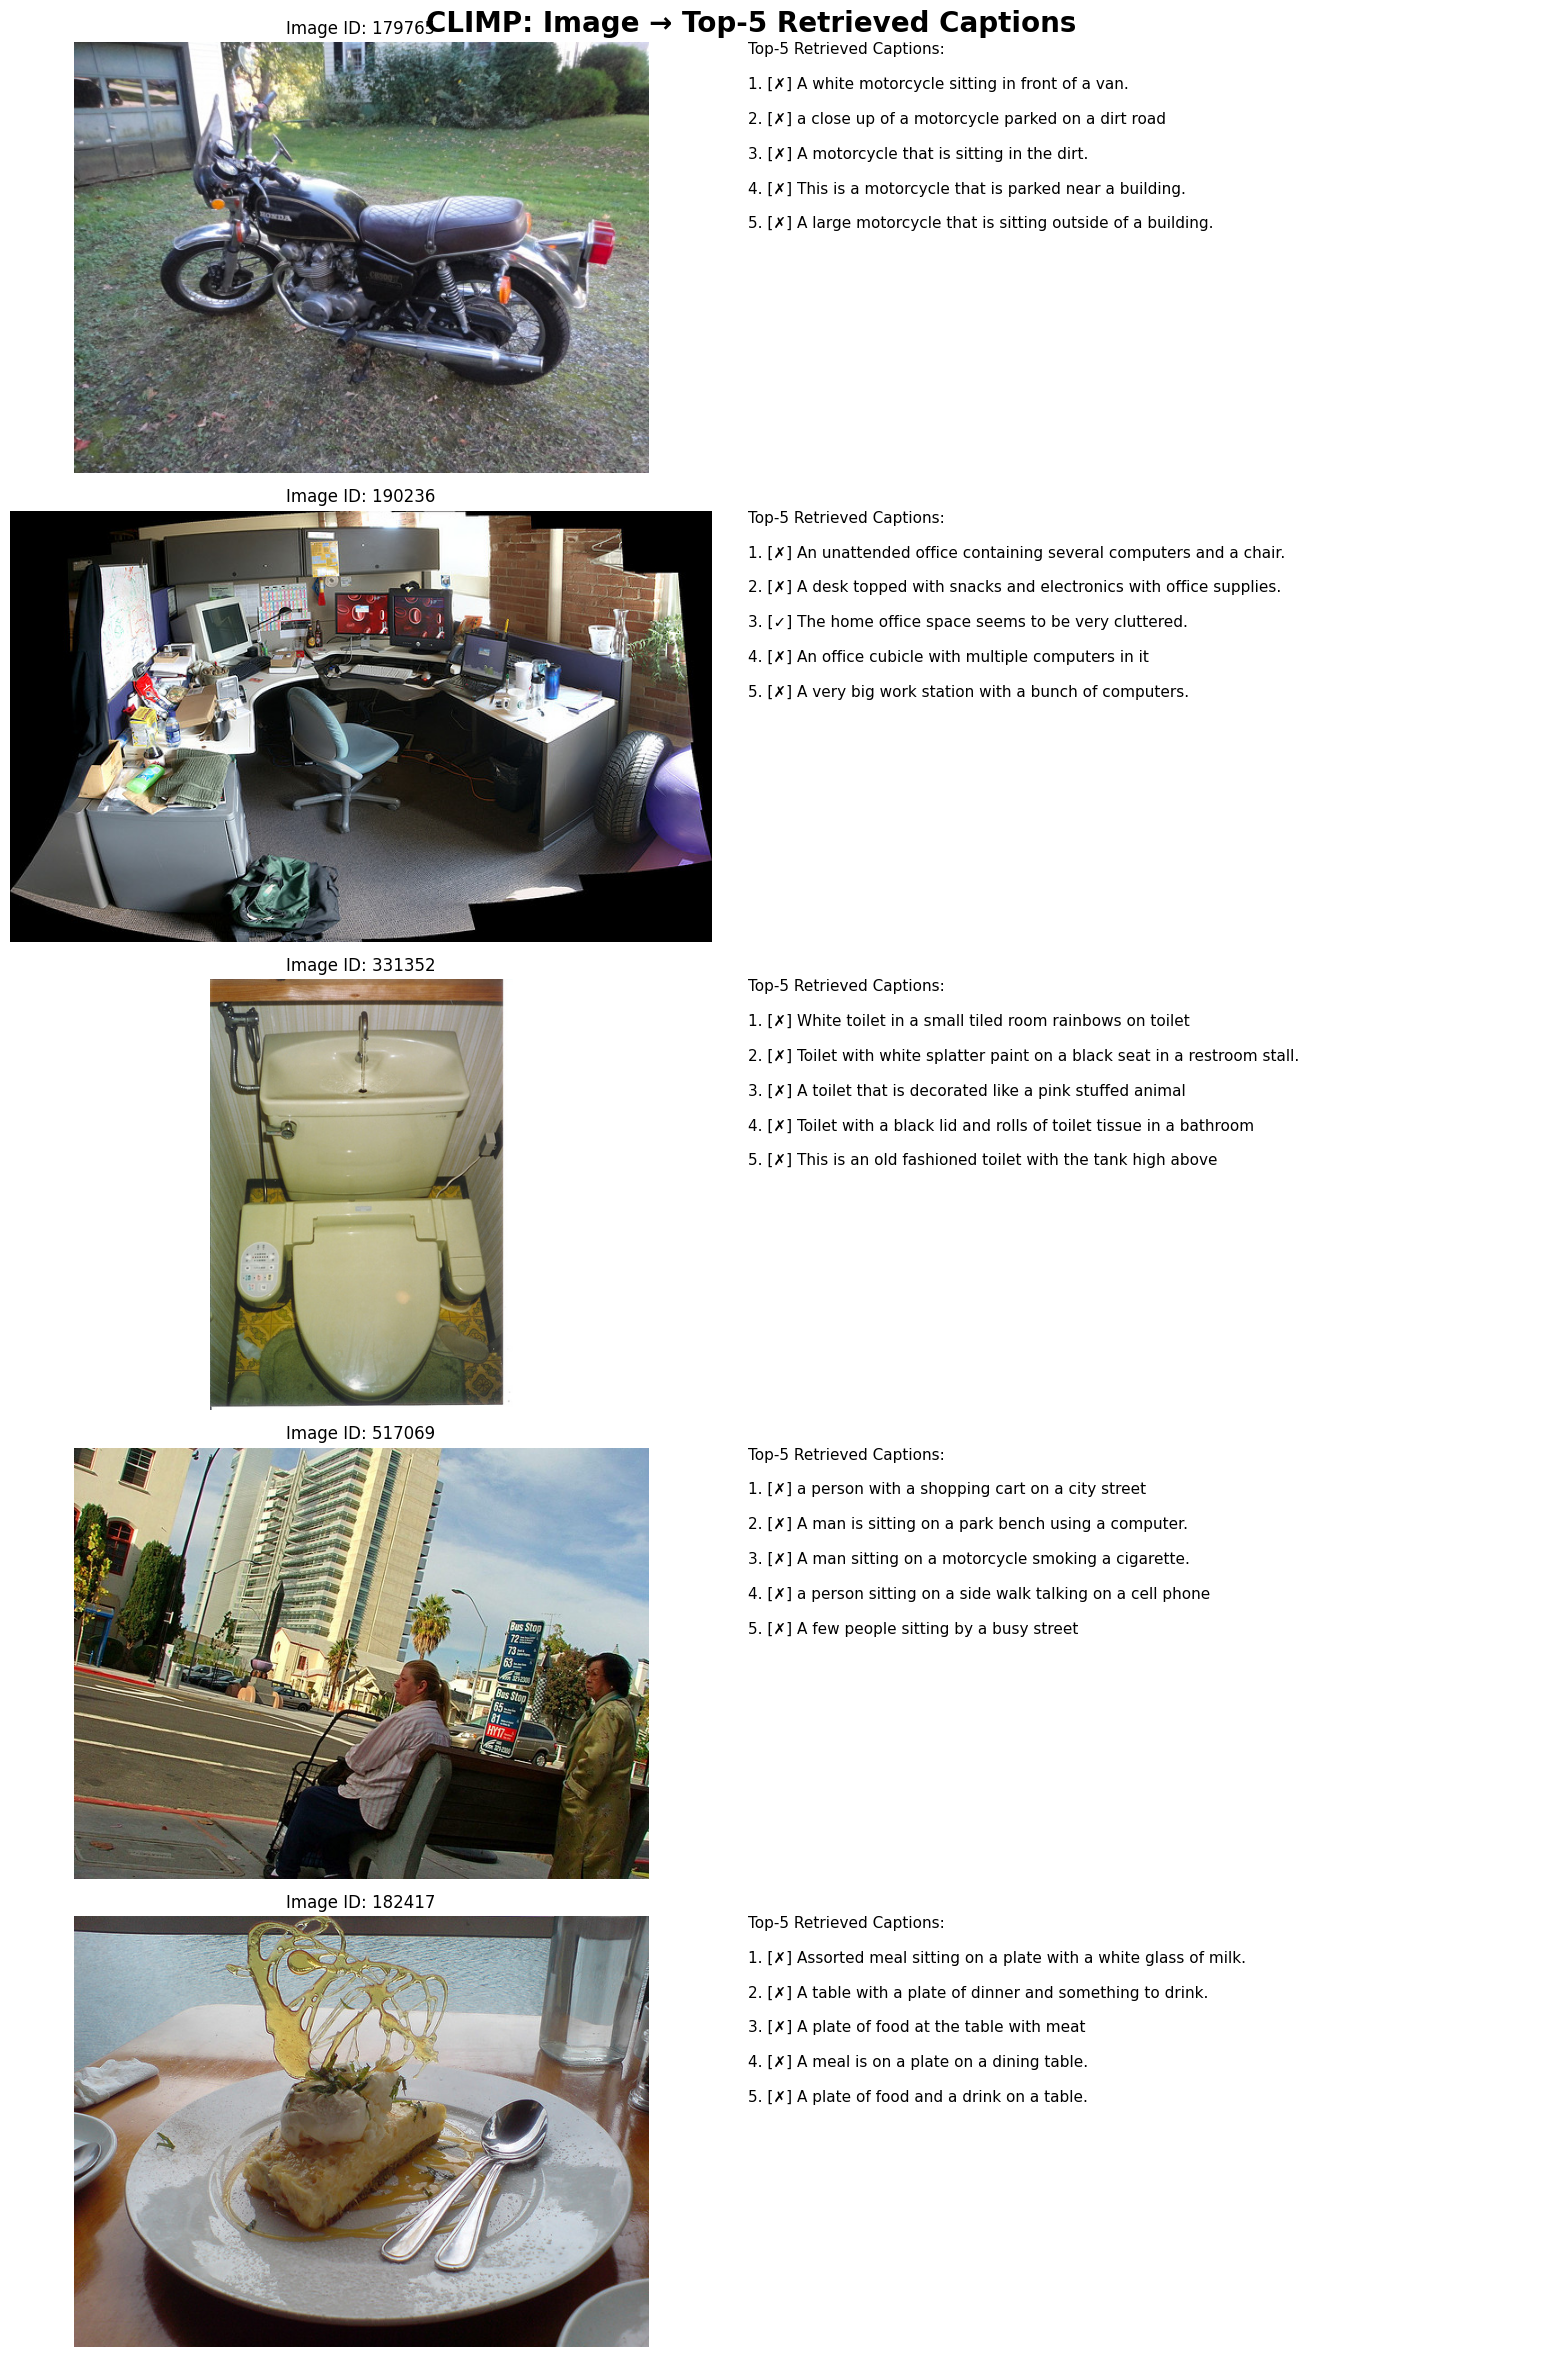

Visualization saved to:
/kaggle/working/climp_retrieval_examples.png


In [39]:
import matplotlib.pyplot as plt


with open(VAL_ANN_FILE, "r") as f:
    val_data = json.load(f)

val_captions = [
    ann["caption"]
    for ann in val_data["annotations"]
]

val_image_ids = [
    ann["image_id"]
    for ann in val_data["annotations"]
]

val_img_map = {
    img["id"]: img["file_name"]
    for img in val_data["images"]
}

selected_image_ids = unique_image_ids[:5]


fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 24)
)

for row, image_id in enumerate(selected_image_ids):

    image_row = unique_image_ids.index(image_id)

    top5_indices = torch.topk(
        similarities[image_row],
        k=5
    ).indices.tolist()
    filename = val_img_map[image_id]
    image_path = os.path.join(
        VAL_IMG_DIR,
        filename
    )

    image = Image.open(image_path).convert("RGB")


    axes[row, 0].imshow(image)
    axes[row, 0].axis("off")
    axes[row, 0].set_title(
        f"Image ID: {image_id}",
        fontsize=12
    )


    axes[row, 1].axis("off")

    caption_text = "Top-5 Retrieved Captions:\n\n"

    for rank, caption_idx in enumerate(top5_indices):

        caption = val_captions[caption_idx]

        caption_image_id = val_image_ids[caption_idx]

        if caption_image_id == image_id:
            marker = "✓"
        else:
            marker = "✗"

        caption_text += (
            f"{rank + 1}. [{marker}] "
            f"{caption}\n\n"
        )

    axes[row, 1].text(
        0,
        1,
        caption_text,
        fontsize=11,
        verticalalignment="top",
        wrap=True
    )

plt.suptitle(
    "CLIMP: Image → Top-5 Retrieved Captions",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()

VIZ_PATH = "/kaggle/working/climp_retrieval_examples.png"

plt.savefig(
    VIZ_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved to:")
print(VIZ_PATH)